# Qiskit Rapid Introduction

A practical introduction for students familiar with quantum computing who want to start using Qiskit.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lounikolaos/Qiskit-rapid-intro/blob/main/Qiskit_Introduction.ipynb)

## 0. Installing Qiskit

This notebook targets Qiskit 2.6.1 and Qiskit Aer 0.18.2 (current stable releases checked on 28 October 2026). Use Python 3.12 for the pinned repository environment (tested with Python 3.12.14). The visualization extra is needed for circuit drawings; Aer is installed separately. SymPy provides primality testing and exact integer roots in the factorization example.

Run the installation cell once in the intended Jupyter kernel. After installing or upgrading packages, restart the kernel, then run the notebook from the imports below.

In [ ]:
%pip install "qiskit[visualization]==2.6.1" "qiskit-aer==0.18.2" sympy

A fresh virtual environment helps avoid package conflicts. See the [Qiskit installation guide](https://quantum.cloud.ibm.com/docs/en/guides/install-qiskit). Select that environment as the Jupyter kernel. The version pins above make this revision reproducible; changing them requires rerunning the examples.

We can now import the packages and display the versions actually loaded by the kernel.

In [2]:
import numpy as np
import qiskit as qi
from importlib.metadata import version

print(f"Qiskit {qi.__version__}; Aer {version('qiskit-aer')}")

Qiskit 2.6.1; Aer 0.18.2


## 1. Circuit Basics

Let's create the Bell state

$$|\phi^+\rangle = \frac{|00\rangle + |11\rangle}{\sqrt{2}}.$$

We use Qiskit's basis ordering $|q_1 q_0\rangle$:

1. Begin in $|00\rangle$.
2. Apply a Hadamard gate to qubit 0, giving $(|00\rangle + |01\rangle)/\sqrt{2}$.
3. Apply a CNOT with control qubit 0 and target qubit 1. It maps $|01\rangle$ to $|11\rangle$, producing $|\phi^+\rangle$.

Let's see this in Qiskit.

First, create a [QuantumCircuit](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.circuit.QuantumCircuit), specifying the number of qubits.

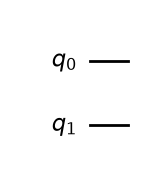

In [3]:
circ = qi.QuantumCircuit(2)
circ.draw(output="mpl")

Apply the gates in order. See the [circuit library](https://quantum.cloud.ibm.com/docs/en/api/qiskit/circuit_library) for more gates.

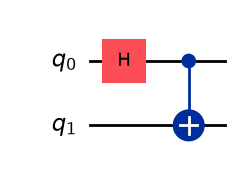

In [4]:
circ.h(0)
circ.cx(0, 1)
circ.draw(output="mpl")

Add measurement instructions with [measure_all](https://quantum.cloud.ibm.com/docs/en/guides/measure-qubits). Here, `inplace=False` creates a measured copy and preserves `circ` for the later statevector example. Adding measurement instructions does not execute the circuit.

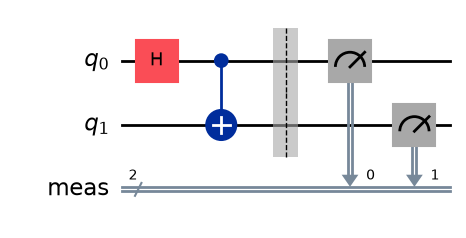

In [5]:
circ_measured = circ.measure_all(inplace=False)
circ_measured.draw(output="mpl")

### Addendum: Registers and measurements

`QuantumRegister` and `ClassicalRegister` let us name groups of qubits and classical bits and choose their sizes explicitly. For example:

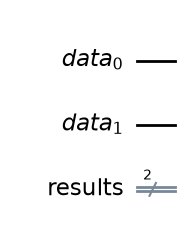

In [6]:
qr = qi.QuantumRegister(2, "data")
cr = qi.ClassicalRegister(2, "results")
qc = qi.QuantumCircuit(qr, cr)
qc.draw(output="mpl")

We can add barriers to separate circuit stages visually. A barrier also constrains compiler transformations across it; it is not a physical quantum gate.

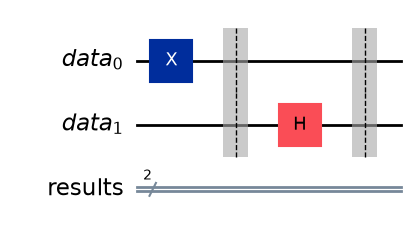

In [7]:
qc.x(qr[0])
qc.barrier()
qc.h(qr[1])
qc.barrier()
qc.draw(output="mpl")

We can measure a particular qubit into a particular classical bit. The following copy measures qubit 0 into classical bit 1 (the second bit of `cr`, not a second register). Using a copy keeps this example independent of the whole-register example below.

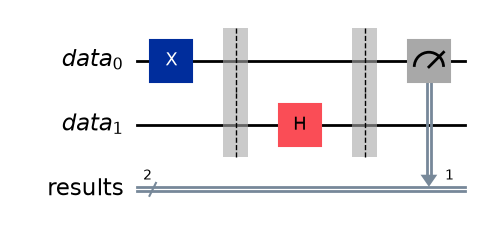

In [8]:
qc_single = qc.copy()
qc_single.measure(qr[0], cr[1])
qc_single.draw(output="mpl")

We can also measure each qubit of `qr` into the corresponding bit of `cr`. The two registers must have matching sizes for this call. If we appended these measurements to `qc_single`, the later result for qubit 1 would overwrite its earlier value in `cr[1]`.

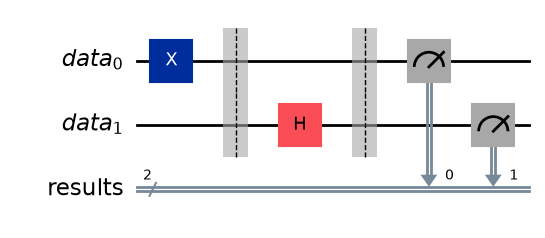

In [9]:
qc_all = qc.copy()
qc_all.measure(qr, cr)
qc_all.draw(output="mpl")

Separate registers are useful when an algorithm also uses ancillary qubits. For example:

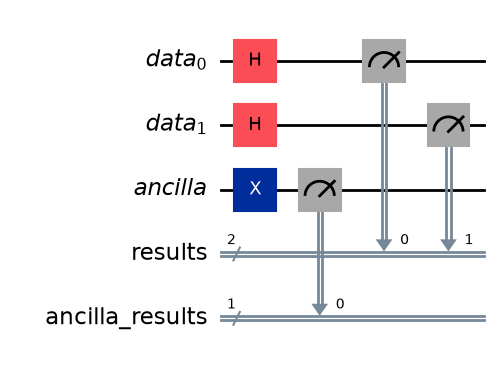

In [10]:
qr = qi.QuantumRegister(2, "data")
ar = qi.QuantumRegister(1, "ancilla")
cr = qi.ClassicalRegister(2, "results")
car = qi.ClassicalRegister(1, "ancilla_results")

qc = qi.QuantumCircuit(qr, ar, cr, car)
qc.h(qr)
qc.x(ar)
qc.measure(ar, car)
qc.measure(qr, cr)
qc.draw(output="mpl")

The quantum and classical registers can be addressed by name without relying on their positions in the whole circuit.

### Simulators

After constructing a circuit, we can simulate it. [Qiskit Aer](https://github.com/Qiskit/qiskit-aer) provides several simulation methods and configurable noise models. We will begin with a noiseless simulation of the measured Bell-state circuit.

Import the simulator and plotting functions.

In [11]:
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram, plot_state_city

Transpilation rewrites the circuit into operations supported by the selected simulator or device. Here, the target is an ideal Aer simulator.

In [12]:
simulator = AerSimulator()
circ_phys = qi.transpile(circ_measured, simulator, seed_transpiler=42)

Measurement results are generally probabilistic. We run 1,000 shots and use the counts to estimate the probabilities. For this ideal Bell state, only `00` and `11` can occur, each with probability 1/2. A finite sample need not contain exactly 500 of each.

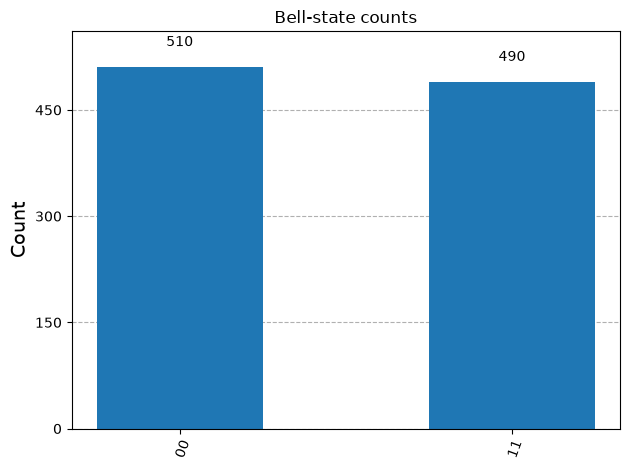

In [13]:
result = simulator.run(circ_phys, shots=1000, seed_simulator=42).result()
counts = result.get_counts(circ_phys)
plot_histogram(counts, title="Bell-state counts")

Computational-basis counts alone do not determine the relative phases of a state. Other measurement bases can reveal relative-phase information; a global phase is unobservable.

For an ideal simulation, we can inspect the full statevector before measurement. Copy the unmeasured Bell circuit and add Aer's `save_statevector` instruction. This instruction is a simulator feature, not a way to read an unknown statevector from hardware.

In [15]:
circ_state = circ.copy()
circ_state.save_statevector()

Use the `statevector` simulation method, transpile, and run. One shot is sufficient here because the circuit contains only ideal unitary gates before the save instruction: there are no measurements, resets, or noise that would introduce stochastic trajectories. `plot_state_city` displays the density matrix corresponding to the statevector.

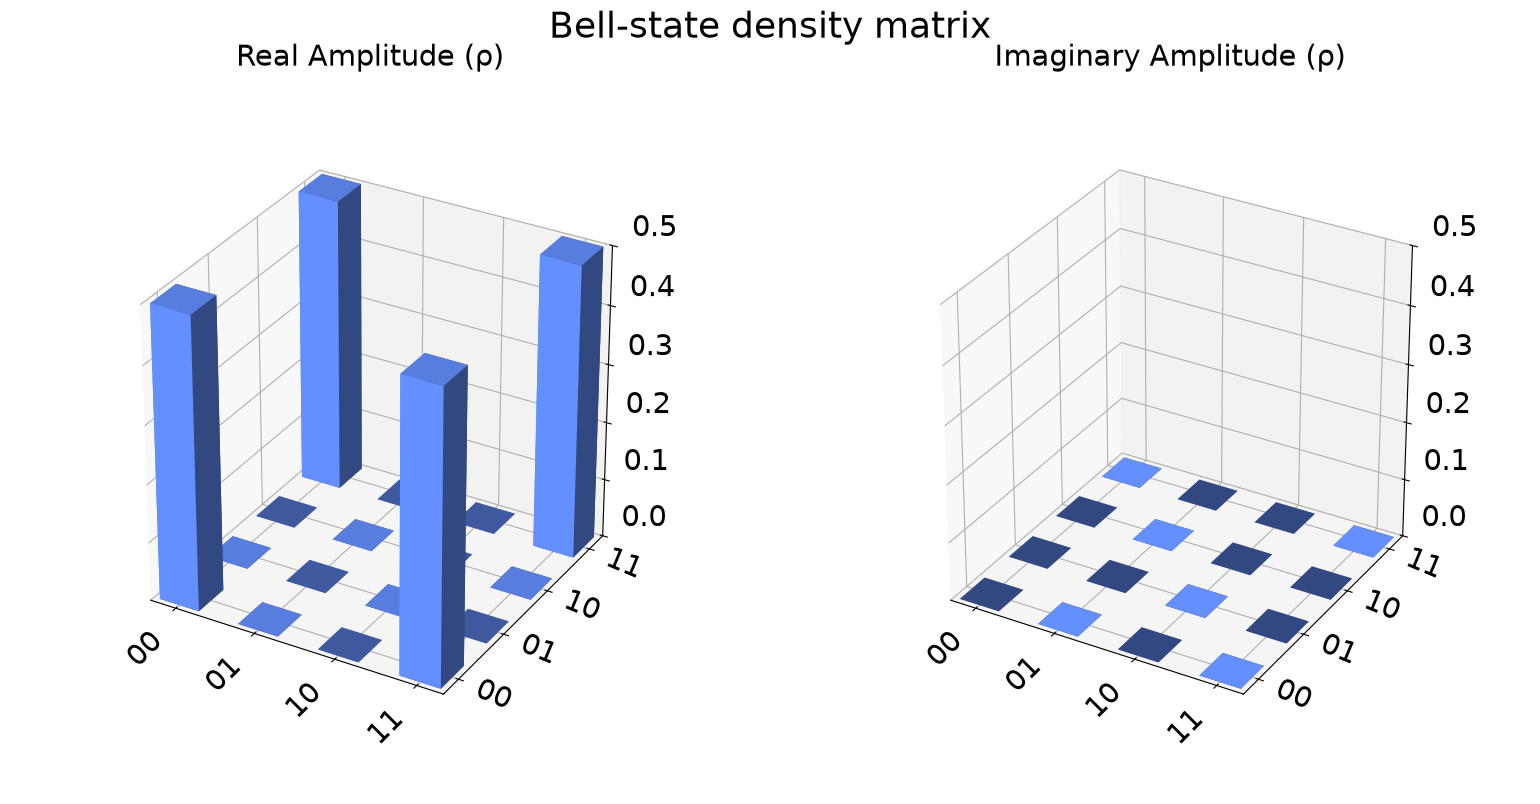

In [16]:
simulator2 = AerSimulator(method="statevector")
circ_phys2 = qi.transpile(circ_state, simulator2, seed_transpiler=42)
result = simulator2.run(circ_phys2, shots=1).result()
statevector = result.get_statevector(circ_phys2)
plot_state_city(statevector, title="Bell-state density matrix")

### Addendum: Order of qubits in Qiskit

Qubit 0 is usually the top wire in a circuit drawing, but it is the **rightmost** bit in a computational-basis label: $|q_{n-1}\cdots q_1 q_0\rangle$. It is the least significant bit when the label is interpreted as an integer.

For two qubits, statevector entries are ordered as $|00\rangle, |01\rangle, |10\rangle, |11\rangle$. Applying an X gate only to qubit 0 therefore prepares $|01\rangle$, whose integer value is 1.

Counts record **classical bits**. When qubit $j$ is measured into classical bit $j$, the usual count string is written $c_{n-1}\cdots c_0$. A different measurement mapping changes what that string says about the qubits. Multiple classical registers are separated by spaces in Aer count strings, with later registers displayed first.

See the [bit-ordering guide](https://quantum.cloud.ibm.com/docs/en/guides/bit-ordering). Changing a drawing's reverse_bits option changes the display, not the circuit's gates or state.

Exercise: Create a circuit for the Bell state

$$|\phi^-\rangle = \frac{|00\rangle - |11\rangle}{\sqrt{2}},$$

and simulate it with the automatic and statevector methods as above. Compare the computational-basis counts and the density-matrix plots with the previous examples. What changes, and what stays the same?

In [ ]:
## Solution:


## 2. Quantum Algorithm Basics (Deutsch–Jozsa)

We will now simulate the Deutsch–Jozsa algorithm (see Nielsen and Chuang, Section 1.4, for background). This is a quantum query algorithm: we assume black-box access to an oracle for a function

$$f:\{0,1\}^n \to \{0,1\}.$$

The function is promised to be either constant, with $f(x)=c$ for every input, or balanced, with equally many inputs producing 0 and 1. We want to distinguish the two cases. The oracle acts as

$$U_f |x\rangle|y\rangle = |x\rangle|y\oplus f(x)\rangle.$$

For $n=1$ and the balanced function $f(0)=0, f(1)=1$, the oracle is a CNOT: it flips the ancilla exactly when the data qubit is 1. Prepare the ancilla in $|-\rangle$ so the oracle encodes $f(x)$ as a relative phase on the data register.

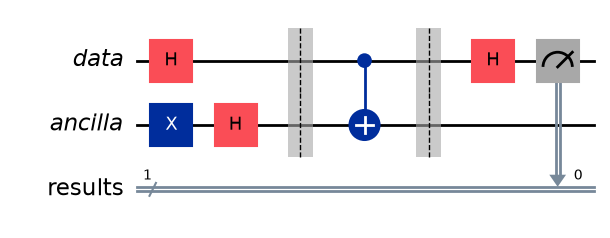

In [18]:
# Initialize one data qubit, one ancilla, and one classical bit.
qr = qi.QuantumRegister(1, "data")
ar = qi.QuantumRegister(1, "ancilla")
cr = qi.ClassicalRegister(1, "results")
qc = qi.QuantumCircuit(qr, ar, cr)

# Prepare |+> on the data qubit and |-> on the ancilla.
qc.h(qr)
qc.x(ar)
qc.h(ar)
qc.barrier()

# Oracle for f(x) = x.
qc.cx(qr[0], ar[0])
qc.barrier()

# Interfere and measure the data qubit.
qc.h(qr)
qc.measure(qr, cr)
qc.draw(output="mpl")

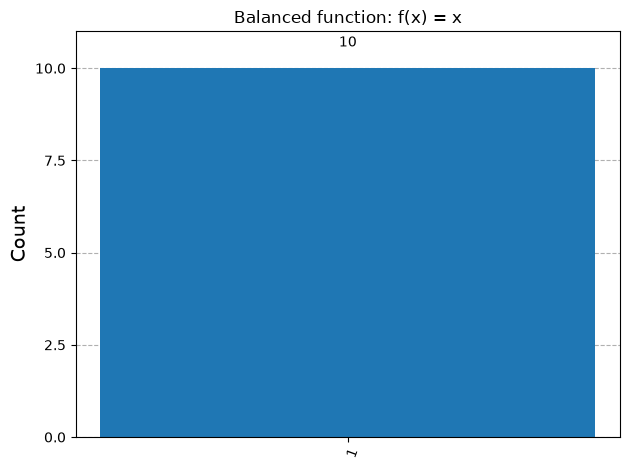

In [19]:
simulator = AerSimulator()
qc_phys = qi.transpile(qc, simulator, seed_transpiler=42)
result = simulator.run(qc_phys, shots=10, seed_simulator=42).result()
counts = result.get_counts(qc_phys)
plot_histogram(counts, title="Balanced function: f(x) = x")

All ideal shots return `1` on the data qubit, identifying the function as balanced.

Now consider the constant function $f(x)=1$. Its oracle always flips the ancilla. For this example we also apply a final Hadamard to the ancilla and measure both qubits, so the output illustrates Qiskit's bit ordering. Measuring the ancilla is not required by the Deutsch–Jozsa algorithm.

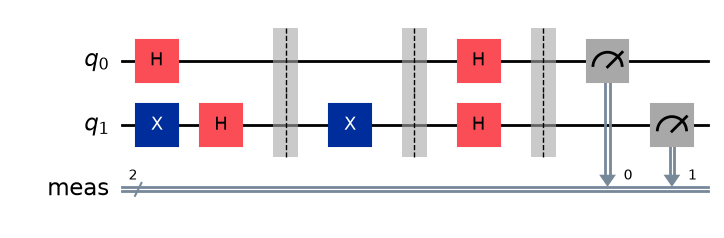

In [21]:
# Create a circuit: qubit 0 is data and qubit 1 is the ancilla.
qc = qi.QuantumCircuit(2)
qc.h(0)
qc.x(1)
qc.h(1)
qc.barrier()

# Oracle for f(x) = 1.
qc.x(1)
qc.barrier()

# Decode the data; rotate the ancilla back for this ordering example.
qc.h(0)
qc.h(1)
qc.measure_all()
qc.draw(output="mpl")

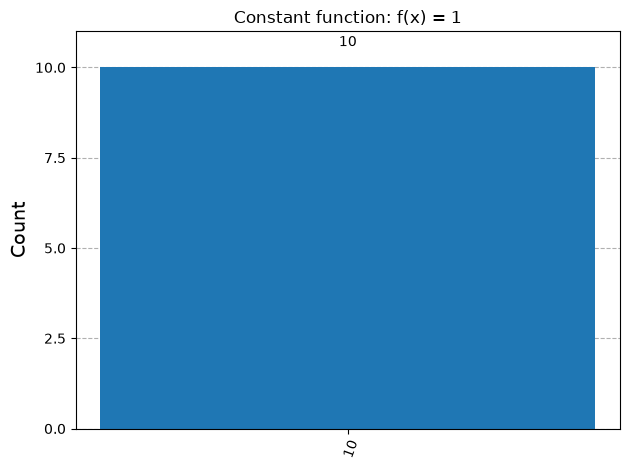

In [22]:
simulator = AerSimulator()
qc_phys = qi.transpile(qc, simulator, seed_transpiler=42)
result = simulator.run(qc_phys, shots=10, seed_simulator=42).result()
counts = result.get_counts(qc_phys)
plot_histogram(counts, title="Constant function: f(x) = 1")

The ideal count string is always 10: data qubit 0 is measured as 0, identifying the constant function, and ancilla qubit 1 is measured as 1. With the identity qubit-to-classical-bit mapping, the string is written $c_1c_0$.

Before measurement the joint state is $-|10\rangle$ in Qiskit's ordering. The overall minus sign is a global phase and has no measurable effect. The final Hadamard maps the ancilla's $-|-\rangle$ to $-|1\rangle$.

There is no unique universal tensor-order convention; always check the labels when translating a circuit from a book or paper.

Exercise: Create a circuit that solves the [Bernstein–Vazirani problem](https://en.wikipedia.org/wiki/Bernstein%E2%80%93Vazirani_algorithm) for an arbitrary secret bit string of length $n=3$. The oracle depends on the chosen string. State explicitly which end of your string corresponds to qubit 0.

In [ ]:
## Solution 

## 3. Shor's Algorithm: Order Finding and Factorization

Suppose we want to factor an integer $N$. Classical preprocessing checks whether $N$ is prime, even, or a perfect power. To obtain a complete prime factorization, find a nontrivial divisor $d$, then apply the same procedure to $d$ and $N/d$ until every remaining factor is prime.

For an odd composite number that is not a prime power, choose $1<a<N$. If $\gcd(a,N)>1$, this already gives a nontrivial factor. Otherwise, the order $r$ of $a$ modulo $N$ is the smallest positive integer satisfying
$$
a^r\equiv1\pmod N.
$$
If $r$ is even, set $x=a^{r/2}\bmod N$. Then
$$
(x-1)(x+1)\equiv0\pmod N.
$$
When $x\notin\{1,N-1\}$, the values $\gcd(x-1,N)$ and $\gcd(x+1,N)$ give nontrivial factors. Every proposed factor must satisfy $1<d<N$.

Under these assumptions, a uniformly chosen coprime base gives a useful even order with probability at least $1/2$. An unsuccessful base can be replaced with another. The quantum subroutine supplies the order-finding step; the gcd calculations are classical.

Order finding uses phase estimation for modular multiplication:
$$
M_a|x\rangle=|ax\bmod N\rangle \qquad (0\leq x<N),
$$
where $\gcd(a,N)=1$. On an $n$-qubit register, define $M_a$ to act as the identity on the unused basis states $N\leq x<2^n$. This makes the entire operation a permutation and hence unitary.

For $s=0,\ldots,r-1$, the states
$$
|u_s\rangle=\frac{1}{\sqrt r}\sum_{k=0}^{r-1}
e^{-2\pi i sk/r}|a^k\bmod N\rangle
$$
satisfy
$$
M_a|u_s\rangle=e^{2\pi i s/r}|u_s\rangle,
\qquad
\frac{1}{\sqrt r}\sum_{s=0}^{r-1}|u_s\rangle=|1\rangle.
$$
Thus we can initialize the work register to $|1\rangle$, without knowing an eigenstate in advance.

We use $n=\lceil\log_2N\rceil$ work qubits and $m=2n+1$ control qubits. Phase estimation produces an integer $y$ such that $y/2^m$ approximates a randomly selected phase $s/r$. The approximation is probabilistic; a single run is not guaranteed to have sufficient accuracy. Continued fractions reconstructs a candidate denominator. Even an accurate sample can yield only a divisor of $r$ when $s$ and $r$ share a factor, so repetitions and classical verification are needed.

The controlled powers use $M_a^{2^k}=M_{a^{2^k}\bmod N}$. Scalable versions of Shor's algorithm implement these operations with polynomial-size reversible arithmetic. Here we explicitly construct dense matrices to keep the example readable. Their storage grows exponentially with $n$, and their synthesis and classical simulation become expensive quickly. This implementation is for small examples such as $N=15$ or $N=21$; it does not demonstrate scalable factoring.

See [IBM's order-finding analysis](https://quantum.cloud.ibm.com/learning/en/courses/fundamentals-of-quantum-algorithms/phase-estimation-and-factoring/shor-algorithm) for the mathematical details.

In [24]:
from qiskit.circuit.library import QFTGate, UnitaryGate
from math import gcd
from numbers import Integral


def _integer_at_least(value, name, minimum=1):
    if isinstance(value, bool) or not isinstance(value, Integral):
        raise ValueError(f"{name} must be an integer.")
    value = int(value)
    if value < minimum:
        raise ValueError(f"{name} must be at least {minimum}.")
    return value


def _validate_order_inputs(a, N):
    N = _integer_at_least(N, "N", 2)
    a = _integer_at_least(a, "a")
    if a >= N:
        raise ValueError("a must satisfy 1 <= a < N.")
    if gcd(a, N) != 1:
        raise ValueError("Order finding requires gcd(a, N) == 1.")
    return a, N


def mod_mult_gate(b, N):
    b, N = _validate_order_inputs(b, N)
    n = (N - 1).bit_length()
    U = np.zeros((2**n, 2**n), dtype=complex)
    for x in range(2**n):
        output = (b * x) % N if x < N else x
        U[output, x] = 1
    return UnitaryGate(U, label=f"M_{b}")


def order_finding_circuit(a, N):
    a, N = _validate_order_inputs(a, N)
    n = (N - 1).bit_length()
    m = 2 * n + 1
    control = qi.QuantumRegister(m, "control")
    target = qi.QuantumRegister(n, "work")
    output = qi.ClassicalRegister(m, "output")
    circuit = qi.QuantumCircuit(control, target, output)

    # Qiskit's least-significant work qubit encodes the integer 1.
    circuit.x(target[0])
    for k, qubit in enumerate(control):
        circuit.h(qubit)
        b = pow(a, 2**k, N)
        circuit.append(
            mod_mult_gate(b, N).control(),
            [qubit] + list(target),
        )

    # QFTGate includes the bit-reversal swaps required by this ordering.
    circuit.append(QFTGate(m).inverse(), control)
    circuit.measure(control, output)
    return circuit

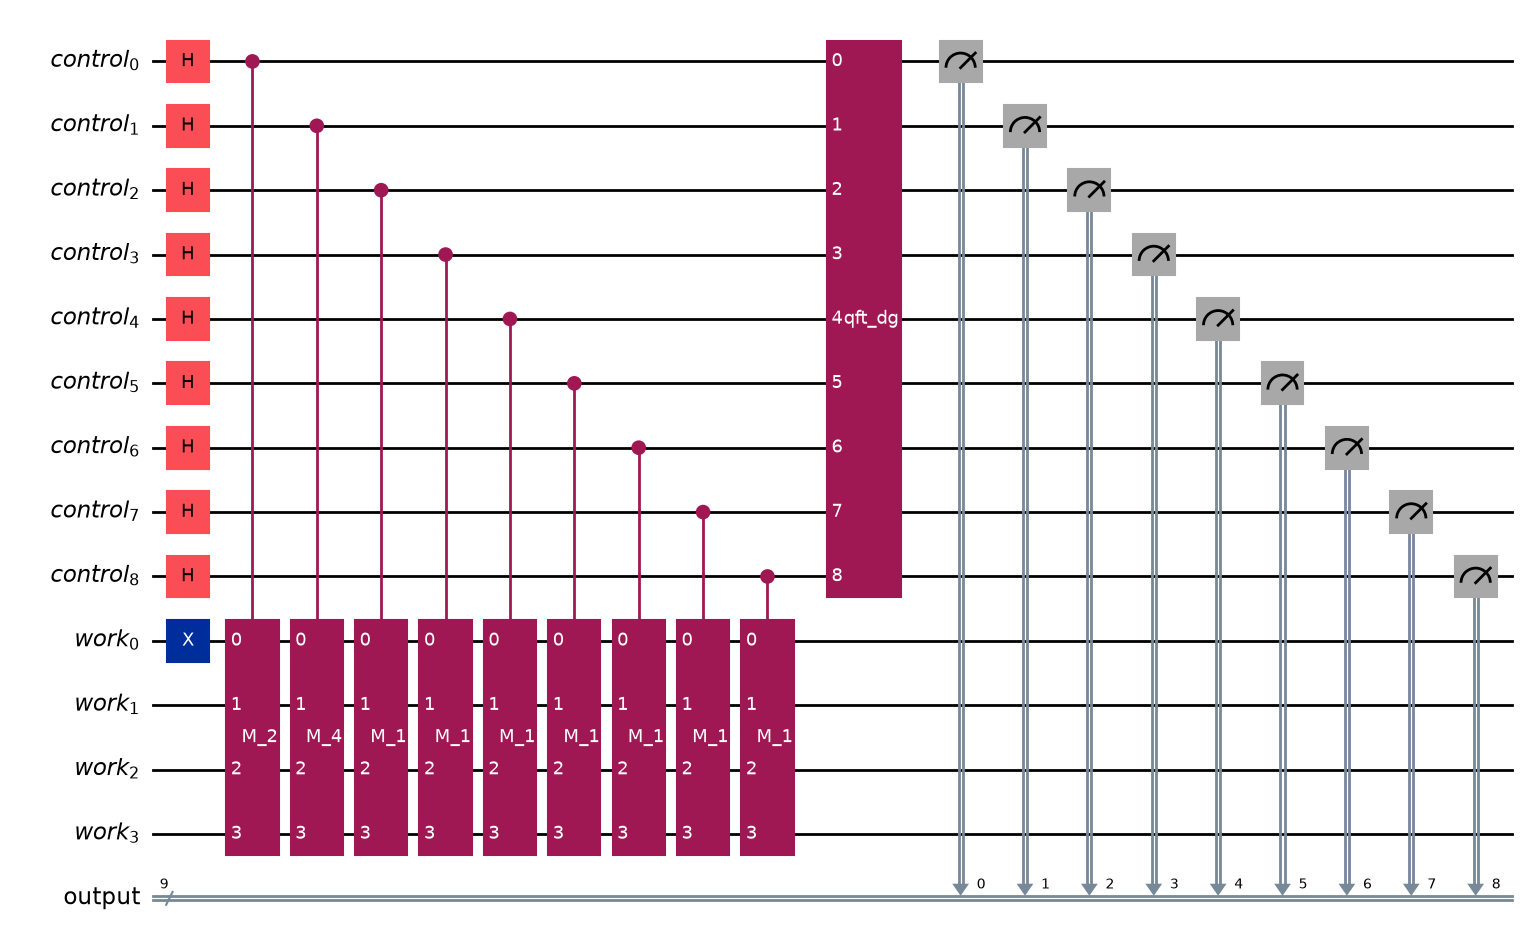

In [26]:
order_finding_circuit(2,15).draw(output = "mpl")

The next routine takes a finite batch of phase-estimation samples. It constructs each rational estimate exactly and checks the candidate exponent with modular arithmetic.

The condition $a^q\equiv1\pmod N$ alone proves that $q$ is a multiple of the order, not necessarily the order itself. For these small examples, we factor the candidate classically and strip any prime factors that can be removed while preserving the modular identity. This produces the minimal order. Trial factoring the candidate is another small-example convenience, not a claim of efficient postprocessing for large integers.

If the batch contains no usable sample, the routine raises an explicit error instead of looping indefinitely.

In [27]:
from fractions import Fraction


def _order_candidate_from_measurement(y, num_control, N):
    num_control = _integer_at_least(num_control, "num_control")
    N = _integer_at_least(N, "N", 2)
    y = _integer_at_least(y, "y", 0)
    if y >= 2**num_control:
        raise ValueError("y does not fit in the control register.")
    return Fraction(y, 2**num_control).limit_denominator(N - 1).denominator


def _minimal_order_from_multiple(a, N, candidate):
    a, N = _validate_order_inputs(a, N)
    candidate = _integer_at_least(candidate, "candidate")
    if pow(a, candidate, N) != 1:
        raise ValueError("The candidate is not a verified multiple of the order.")

    order = candidate
    remaining = candidate
    prime = 2
    while prime * prime <= remaining:
        if remaining % prime == 0:
            while remaining % prime == 0:
                remaining //= prime
            while order % prime == 0 and pow(a, order // prime, N) == 1:
                order //= prime
        prime += 1
    if remaining > 1:
        while order % remaining == 0 and pow(a, order // remaining, N) == 1:
            order //= remaining
    return order


def find_order(a, N, max_shots=128, seed=None):
    a, N = _validate_order_inputs(a, N)
    max_shots = _integer_at_least(max_shots, "max_shots")
    if seed is not None:
        seed = _integer_at_least(seed, "seed", 0)
    if a == 1:
        return 1

    circuit = order_finding_circuit(a, N)
    simulator = AerSimulator(method="statevector")
    compiled = qi.transpile(
        circuit, simulator, optimization_level=1, seed_transpiler=seed
    )
    result = simulator.run(
        compiled,
        shots=max_shots,
        memory=True,
        seed_simulator=seed,
    ).result()

    for bitstring in result.get_memory():
        y = int(bitstring.replace(" ", ""), 2)
        candidate = _order_candidate_from_measurement(y, circuit.num_clbits, N)
        if pow(a, candidate, N) == 1:
            return _minimal_order_from_multiple(a, N, candidate)
    raise RuntimeError(
        f"No order was recovered from {max_shots} shots for a={a}, N={N}."
    )

We can now combine order finding with classical preprocessing to obtain one nontrivial factor. The function keeps the name prime_factor for continuity, but its returned divisor is not necessarily prime. A complete prime factorization would recursively factor the divisor and its complementary factor.

Sympy supplies the primality check and exact integer-root checks. Prime inputs are rejected because they have no nontrivial divisor. Both the base-selection loop and each order-finding batch have explicit limits.

In [29]:
import random
from sympy import isprime, integer_nthroot


def prime_factor(N, max_attempts=20, max_shots=128, seed=None):
    """Return one proper divisor of a composite integer N."""
    N = _integer_at_least(N, "N", 2)
    max_attempts = _integer_at_least(max_attempts, "max_attempts")
    max_shots = _integer_at_least(max_shots, "max_shots")
    if seed is not None:
        seed = _integer_at_least(seed, "seed", 0)
    if isprime(N):
        raise ValueError(f"{N} is prime and has no nontrivial factor.")
    if N % 2 == 0:
        return 2

    # A perfect-power root is a factor; it need not itself be prime.
    for exponent in range(2, N.bit_length()):
        root, exact = integer_nthroot(N, exponent)
        if exact and 1 < root < N:
            return int(root)

    rng = random.Random(seed)
    for _ in range(max_attempts):
        a = rng.randrange(2, N)
        divisor = gcd(a, N)
        if 1 < divisor < N:
            return divisor

        try:
            order = find_order(
                a, N, max_shots=max_shots, seed=rng.randrange(2**32)
            )
        except RuntimeError:
            continue
        if order % 2:
            continue

        x = pow(a, order // 2, N)
        for value in (x - 1, x + 1):
            divisor = gcd(value, N)
            if 1 < divisor < N:
                return divisor

    raise RuntimeError(
        f"No nontrivial factor found in {max_attempts} attempts for N={N}."
    )

In [31]:
# Exercise the quantum order-finding circuit explicitly.
print("Order of 2 modulo 15:", find_order(2, 15, seed=42))

# With seed=5 the first base is 10, which is coprime to 21.
# This example therefore proceeds through order finding.
factor = prime_factor(21, seed=5)
print(f"21 = {factor} x {21 // factor}")

Order of 2 modulo 15: 4


21 = 3 x 7


To explore the effect of errors, we will add an illustrative noise model to the Aer simulator. We omit single-qubit and readout errors here to isolate the effect of noise after two-qubit gates. This is a modeling choice, not a universal statement about hardware error rates. It does not predict the performance of a particular device.

In [32]:
# An illustrative basis: CNOT and single-qubit rotations.
basis = ["cx", "rx", "ry", "rz"]

A simple noise model applies a depolarizing channel after every CX gate. With parameter $\lambda=0.1$ on two qubits, this channel is
$$
\mathcal{E}(\rho)=0.9\rho+0.1\frac{I_4}{4}.
$$
The parameter is the channel's depolarizing strength; it should not be equated directly with a device's quoted gate-error probability. See [Aer's depolarizing-error definition](https://qiskit.github.io/qiskit-aer/stubs/qiskit_aer.noise.depolarizing_error.html).

In [33]:
from qiskit_aer.noise import NoiseModel, depolarizing_error

depolarizing_noise_model = NoiseModel()
error = depolarizing_error(0.1, 2)
depolarizing_noise_model.add_all_qubit_quantum_error(error, ["cx"])

For a fair comparison, we transpile once into the chosen gate basis and run that same circuit both without noise and with the noise model. Both runs use a fixed number of shots. The statevector simulation method keeps this 13-qubit example manageable; with noise it samples stochastic trajectories.

We report two metrics. A direct denominator match means that the raw continued-fraction denominator equals the known order. Verified recovery applies the same modular verification and candidate reduction as find_order. A multiple of the true order can fail the first metric but succeed on the second.

Every shot contributes to both metrics. There are no retries or discarded results. These are per-shot recovery rates, not the success probability of the full factoring routine.

In [34]:
def order_candidate_statistics(counts, num_control, a, N, expected_order):
    candidate_counts = {}
    verified_recoveries = 0
    for bitstring, count in counts.items():
        y = int(bitstring.replace(" ", ""), 2)
        candidate = _order_candidate_from_measurement(y, num_control, N)
        candidate_counts[candidate] = candidate_counts.get(candidate, 0) + count
        if pow(a, candidate, N) == 1:
            recovered = _minimal_order_from_multiple(a, N, candidate)
            if recovered == expected_order:
                verified_recoveries += count

    shots = sum(counts.values())
    correct = candidate_counts.get(expected_order, 0)
    return {
        "shots": shots,
        "correct_raw_candidates": correct,
        "other_raw_candidates": shots - correct,
        "success_rate": correct / shots if shots else 0.0,
        "verified_recoveries": verified_recoveries,
        "rejected_candidates": shots - verified_recoveries,
        "verified_recovery_rate": verified_recoveries / shots if shots else 0.0,
        "candidate_counts": dict(sorted(candidate_counts.items())),
    }


def compare_order_finding_noise(a, N, expected_order, shots=64, seed=42):
    a, N = _validate_order_inputs(a, N)
    shots = _integer_at_least(shots, "shots")
    expected_order = _integer_at_least(expected_order, "expected_order")
    if _minimal_order_from_multiple(a, N, expected_order) != expected_order:
        raise ValueError("expected_order must be the true minimal order.")
    if seed is not None:
        seed = _integer_at_least(seed, "seed", 0)

    circuit = order_finding_circuit(a, N)
    compiled = qi.transpile(
        circuit, basis_gates=basis, optimization_level=1, seed_transpiler=seed
    )
    ideal_simulator = AerSimulator(method="statevector")
    noisy_simulator = AerSimulator(
        method="statevector", noise_model=depolarizing_noise_model
    )

    comparison = {"circuit": compiled}
    for label, simulator in (("ideal", ideal_simulator), ("noisy", noisy_simulator)):
        counts = simulator.run(
            compiled, shots=shots, seed_simulator=seed
        ).result().get_counts()
        comparison[f"{label}_counts"] = counts
        comparison[label] = order_candidate_statistics(
            counts, circuit.num_clbits, a, N, expected_order
        )
    return comparison

For $a=2$ and $N=15$, the true order is $4$. In the ideal circuit, the phases $0$, $1/4$, $1/2$, and $3/4$ each occur with probability $1/4$. Their reduced denominators are $1$, $4$, $2$, and $4$, respectively. Thus the ideal direct-match rate is $1/2$, not $1$. For these ideal outcomes, the verified recovery rate is also $1/2$.

Under noise, a raw candidate such as $8$ or $12$ is a multiple of the true order and can be reduced to $4$. The two reported metrics can therefore differ. The comparison below reports exact counts from 64 shots per condition. Finite samples fluctuate; the histogram includes every raw candidate denominator.

Ideal — direct denominator match: 31/64 (48.4%); 33 other denominators
  Verified order recovery: 31/64 (48.4%); 33 rejected candidates
  Raw candidate counts: {1: 14, 2: 19, 4: 31}
Noisy — direct denominator match: 2/64 (3.1%); 62 other denominators
  Verified order recovery: 7/64 (10.9%); 57 rejected candidates
  Raw candidate counts: {1: 5, 2: 4, 3: 2, 4: 2, 5: 1, 6: 2, 7: 8, 8: 3, 9: 4, 10: 1, 11: 7, 12: 2, 13: 10, 14: 13}


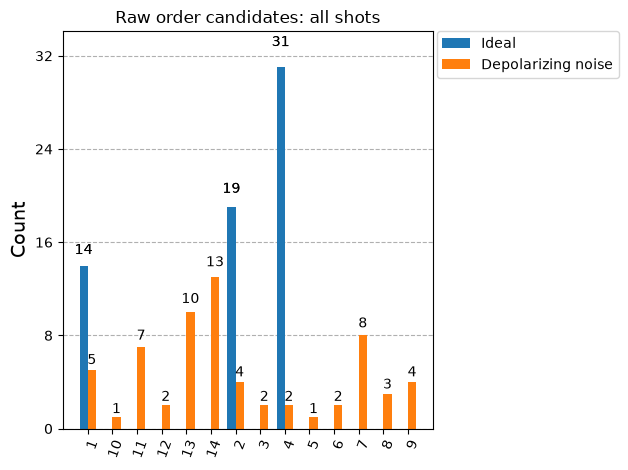

In [35]:
comparison = compare_order_finding_noise(2, 15, expected_order=4, shots=64, seed=42)

for label in ("ideal", "noisy"):
    stats = comparison[label]
    print(
        f"{label.capitalize()} — direct denominator match: "
        f"{stats['correct_raw_candidates']}/{stats['shots']} "
        f"({stats['success_rate']:.1%}); "
        f"{stats['other_raw_candidates']} other denominators"
    )
    print(
        f"  Verified order recovery: {stats['verified_recoveries']}/{stats['shots']} "
        f"({stats['verified_recovery_rate']:.1%}); "
        f"{stats['rejected_candidates']} rejected candidates"
    )
    print("  Raw candidate counts:", stats["candidate_counts"])

plot_histogram(
    [
        {str(candidate): count for candidate, count in comparison[label]["candidate_counts"].items()}
        for label in ("ideal", "noisy")
    ],
    legend=["Ideal", "Depolarizing noise"],
    title="Raw order candidates: all shots",
)

We can also inspect how the order-finding circuit decomposes into our chosen gate basis.

The full decomposed drawing is very large. Its display is optional: set `SHOW_FULL_CIRCUIT = True` in the final drawing cell to render it.

In [37]:
circ = order_finding_circuit(2, 15)

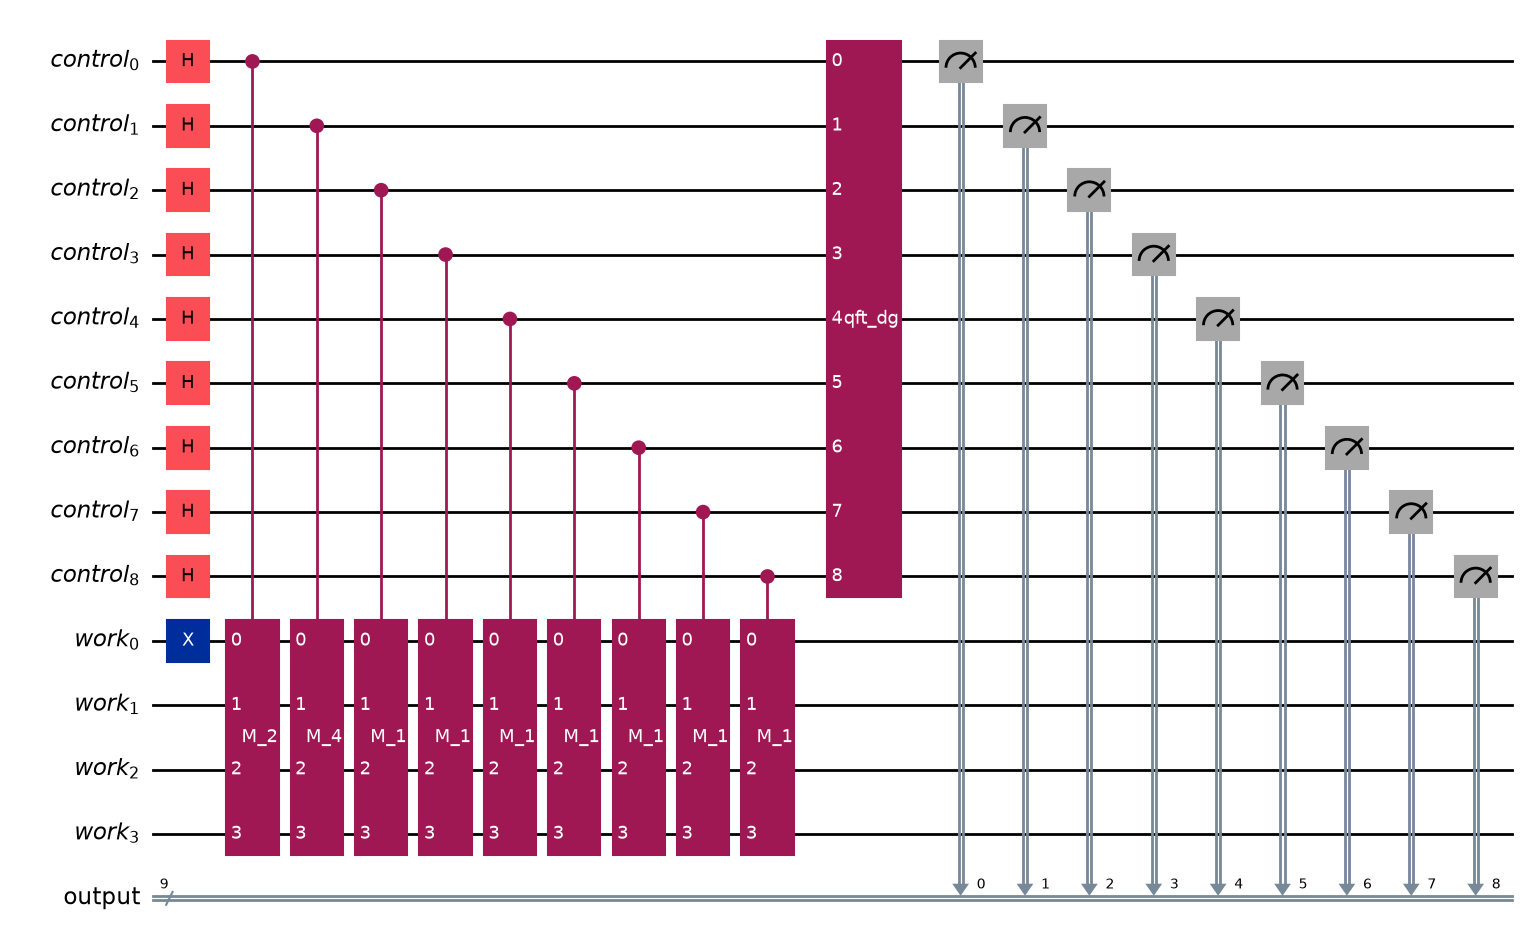

In [38]:
circ.draw(output="mpl")

In [39]:
circ = qi.transpile(
    circ, basis_gates=basis, optimization_level=1, seed_transpiler=42
)

In [ ]:
# Enable this to display the full decomposed circuit.
SHOW_FULL_CIRCUIT = False

if SHOW_FULL_CIRCUIT:
    from IPython.display import display
    display(circ.draw(output="mpl", fold=100))

This circuit uses the chosen illustrative basis. A real device may have different native instructions and restricted connectivity, so hardware transpilation can introduce additional gates and routing. The dense-unitary construction used here can also produce much larger circuits than a purpose-built modular-arithmetic implementation.

Exercise: The noise model above is deliberately simple. Compare the order-finding circuit with a device-derived noise model using the [Aer device-noise tutorial](https://qiskit.github.io/qiskit-aer/tutorials/2_device_noise_simulation.html). Use the same finite-shot metrics and transpile for the chosen backend's instructions and connectivity. A model based on stored calibration data is still an approximation to hardware behavior; accessing a live device is not required for this exercise.

In [ ]:
##Solution: